# Mini-projet Séries Temporelles — Partie 1 : Données & analyse exploratoire
**Électricité et chaleur en Tunisie** (thématique B — environnement/énergie)

**Justification du choix (1 phrase)** : la Tunisie subit depuis plusieurs étés des tensions sur le réseau électrique lors des pics de chaleur (coupures aux heures de pointe), ce qui fait de la relation *température → production/consommation d'électricité* un problème réel et directement utile à anticiper.

**Question de modélisation** : peut-on prévoir la production mensuelle d'électricité (proxy de la demande) à horizon 5–10 mois, et la température apporte-t-elle une information utile au-delà de la saisonnalité ?

Ce notebook couvre les sections 1 et 2 de l'énoncé (importation, préparation, analyse exploratoire). **Toute l'exploration est faite sur l'échantillon d'apprentissage uniquement** (pas de fuite d'information depuis le test).

## 0. Environnement et reproductibilité
Dossier attendu : `data/` à côté du notebook, contenant les deux fichiers sources listés ci-dessous. Les versions de packages sont dans `requirements.txt`.

In [1]:
import warnings, platform, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)          # graine fixée (reproductibilité)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| statsmodels", statsmodels.__version__)

python 3.14.7 | pandas 3.0.6 | numpy 2.5.3 | statsmodels 0.15.0


## 1. Données : sources, construction, découpage

**Sources**
- **Production d'électricité** : fichier open data tunisien « production mensuelle d'électricité par producteurs » (`opendataproductionmensuelleelectriciteparproducteurs.xlsx`), mensuel, janv. 2005 – août 2024. *(À compléter : URL/portail officiel exact d'où le fichier a été téléchargé.)*
- **Température** : API historique **Open-Meteo** (`open-meteo-36_80N10_17E14m.csv`), journalier, point de grille 36,80°N / 10,17°E (Tunis), janv. 2005 – août 2024. Ce sont des données de **réanalyse** (maillage interpolé), pas des mesures d'une station : à signaler comme limite.

**Transformations déjà présentes dans les données du fournisseur (à documenter)**
1. Les dates du fichier de production sont mixtes (texte `1 / 2005`, puis numéros de série Excel).
2. À partir de janv. 2020, la colonne « Production totale » contient des formules Excel et non des valeurs : on **recalcule** le total.
3. Les IPP (producteurs indépendants) tombent à 0 à partir de juin 2022 (intégrés à la STEG) ; auto-producteurs et solaire IPP n'apparaissent qu'à partir de janv. 2023 (≈ 0,3–4 % du total). Pour éviter une rupture artificielle de définition, la **série cible** est `core = STEG + IPP`, continue sur toute la période.
4. Le fichier Excel est en réalité un ancien format `.xls` : lecture avec `xlrd`.

In [11]:
DATA = "data"

prod = pd.read_excel(
    f"{DATA}/opendataproductionmensuelleelectriciteparproducteurs (1).xlsx"
)
prod.columns = ["date", "steg", "ipp", "ipp_solar", "auto", "total_raw"]

def parse_month(v):
    # dates mixtes : texte "m / aaaa" ou numéro de série Excel -> on unifie en Period mensuelle
    if isinstance(v, str):
        m, y = [int(t) for t in v.split("/")]
        return pd.Period(f"{y}-{m:02d}", "M")
    return (pd.Timestamp("1899-12-30") + pd.Timedelta(days=float(v))).to_period("M")

prod["month"] = prod["date"].map(parse_month)
prod = prod.set_index("month").drop(columns=["date", "total_raw"])       # total_raw : formules -> recalculé
prod[["ipp_solar", "auto"]] = prod[["ipp_solar", "auto"]].fillna(0)      # absents avant 2023
prod["production_gwh"] = prod[["steg", "ipp", "ipp_solar", "auto"]].sum(axis=1)   # total recalculé
prod["core"] = prod["steg"] + prod["ipp"]                                # cible : définition constante

# --- Température : journalier -> mensuel ------------------------------------------------------
w = pd.read_csv(f"{DATA}/open-meteo-36.80N10.17E14m.csv", skiprows=3)
w.columns = ["date", "tmean", "tmax", "tmin"]
w["date"] = pd.to_datetime(w["date"]); w["month"] = w["date"].dt.to_period("M")
temp = w.groupby("month").agg(
    t_mean=("tmean", "mean"), t_max_mean=("tmax", "mean"), t_max_peak=("tmax", "max"),
    t_min_mean=("tmin", "mean"),
    days_above_35=("tmax", lambda s: int((s > 35).sum())),          # jours de forte chaleur
    cdd24=("tmean", lambda s: float((s - 24).clip(lower=0).sum())))  # degrés-jours de climatisation (> 24 °C)

df = prod.join(temp, how="inner")
df.index = df.index.to_timestamp(); df.index.name = "month"; df.index.freq = "MS"   # fréquence déclarée
df["covid_2020_04"] = ((df.index == "2020-04-01")).astype(int)          # indicatrice (justifiée en section 2.5)
df.round(3).to_csv(f"{DATA}/monthly_dataset.csv")

print(df.shape, df.index.min().date(), "->", df.index.max().date(), "| valeurs manquantes :", int(df.isna().sum().sum()))
assert df.index.to_series().diff().dropna().dt.days.between(28, 31).all()   # aucun mois manquant
df[["core", "production_gwh", "t_mean", "t_max_mean", "days_above_35", "cdd24"]].describe().round(1)

(236, 13) 2005-01-01 -> 2024-08-01 | valeurs manquantes : 0


,core,production_gwh,t_mean,t_max_mean,days_above_35,cdd24
count,236.0,236.0,236.0,236.0,236.0,236.0
mean,1407.5,1410.6,18.9,24.0,2.2,25.0
std,323.4,326.4,5.9,6.7,4.6,43.4
min,883.8,883.8,8.7,12.3,0.0,0.0
25%,1181.7,1181.7,13.2,17.8,0.0,0.0
50%,1379.2,1380.5,18.0,23.3,0.0,0.0
75%,1532.7,1535.4,24.2,29.9,2.0,32.5
max,2492.6,2541.9,31.4,40.1,24.0,228.4


In [12]:
# Découpage CHRONOLOGIQUE 90 % / 10 % (jamais aléatoire)
N_TRAIN = int(0.9 * len(df))
train, test = df.iloc[:N_TRAIN].copy(), df.iloc[N_TRAIN:].copy()
print(f"train : {train.index[0]:%Y-%m} -> {train.index[-1]:%Y-%m}  ({len(train)} mois)")
print(f"test  : {test.index[0]:%Y-%m} -> {test.index[-1]:%Y-%m}  ({len(test)} mois)")

train : 2005-01 -> 2022-08  (212 mois)
test  : 2022-09 -> 2024-08  (24 mois)


Le test (sept. 2022 – août 2024) contient **les étés 2023 et 2024**, qui sont des pics bien plus élevés que tout ce que l'apprentissage a vu : c'est un test volontairement difficile, à rappeler quand on interprétera les erreurs de prévision.

## 2. Analyse exploratoire (échantillon d'apprentissage)
### 2.1 Visualisation des séries

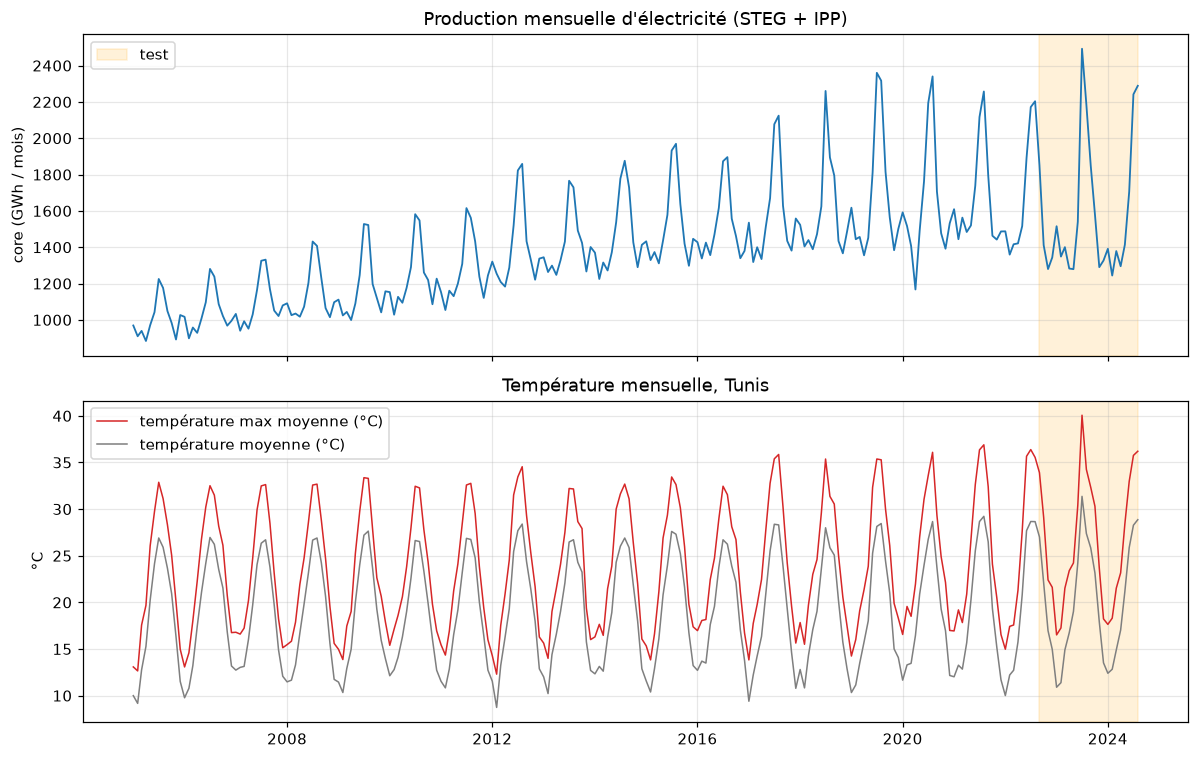

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(df.index, df["core"], color="tab:blue", lw=1.2)
ax[0].axvspan(test.index[0], test.index[-1], color="orange", alpha=.15, label="test")
ax[0].set_ylabel("core (GWh / mois)"); ax[0].set_title("Production mensuelle d'électricité (STEG + IPP)"); ax[0].legend()
ax[1].plot(df.index, df["t_max_mean"], color="tab:red", lw=1.0, label="température max moyenne (°C)")
ax[1].plot(df.index, df["t_mean"], color="tab:gray", lw=1.0, label="température moyenne (°C)")
ax[1].axvspan(test.index[0], test.index[-1], color="orange", alpha=.15)
ax[1].set_ylabel("°C"); ax[1].legend(); ax[1].set_title("Température mensuelle, Tunis")
plt.tight_layout(); plt.show()

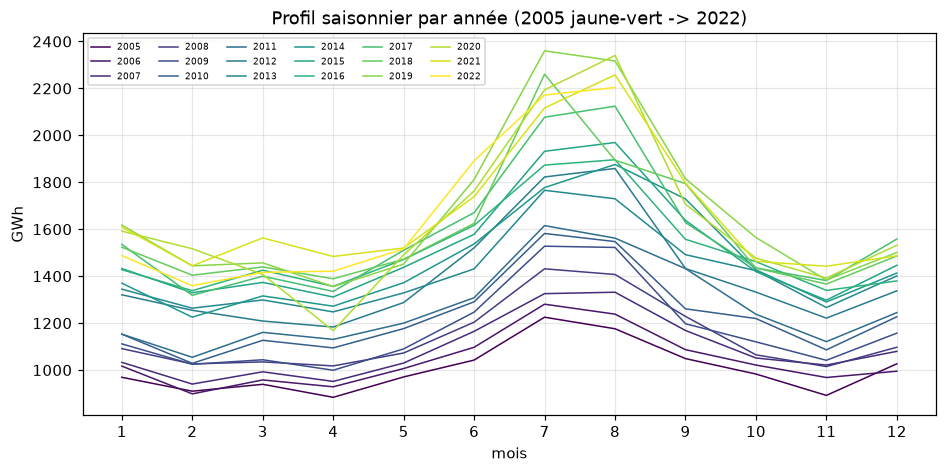

corr(amplitude brute, niveau annuel) = 0.88
coef. de variation de l'amplitude : brute = 0.35 | log = 0.21


month,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
niveau moyen,1006.00,1041.00,1091.00,1141.00,1174.00,1233.00,1268.00,1398.00,1416.00,1467.00,1514.00,1512.00,1581.00,1591.0,1673.00,1631.0,1660.00,1683.00
amplitude brute,341.00,382.00,391.00,416.00,528.00,553.00,561.00,675.00,518.00,651.00,672.00,558.00,806.00,894.0,1005.00,1173.0,815.00,844.00
amplitude log,0.33,0.35,0.35,0.34,0.42,0.43,0.43,0.45,0.35,0.43,0.42,0.35,0.48,0.5,0.55,0.7,0.45,0.48


In [14]:
# Graphique saisonnier : une courbe par année -> le profil est-il stable ? l'amplitude change-t-elle ?
fig, ax = plt.subplots(figsize=(10, 4.5))
cmap = plt.cm.viridis(np.linspace(0, 1, train.index.year.nunique()))
for c, (yr, g) in zip(cmap, train.groupby(train.index.year)):
    ax.plot(g.index.month, g["core"], color=c, lw=1, label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xlabel("mois"); ax.set_ylabel("GWh")
ax.set_title("Profil saisonnier par année (2005 jaune-vert -> 2022)"); ax.legend(ncol=6, fontsize=6)
plt.show()

# Amplitude saisonnière annuelle : brute vs logarithmique
g = train["core"].groupby(train.index.year)
rng_raw = g.max() - g.min(); lvl = g.mean(); rng_log = np.log(train["core"]).groupby(train.index.year).agg(lambda s: s.max() - s.min())
print("corr(amplitude brute, niveau annuel) =", round(np.corrcoef(rng_raw, lvl)[0, 1], 2))
print("coef. de variation de l'amplitude : brute =", round(rng_raw.std() / rng_raw.mean(), 2),
      "| log =", round(rng_log.std() / rng_log.mean(), 2))
pd.DataFrame({"niveau moyen": lvl.round(0), "amplitude brute": rng_raw.round(0), "amplitude log": rng_log.round(2)}).T

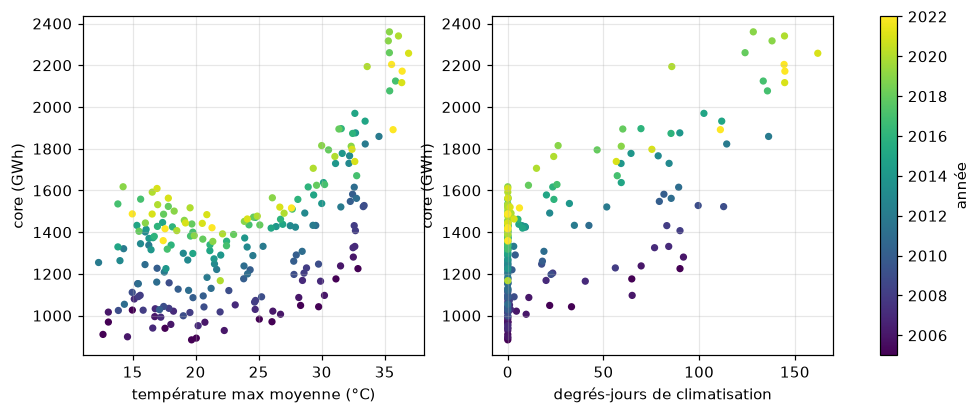

corr. brute (niveaux)       : {'core': 1.0, 't_mean': 0.57, 't_max_mean': 0.62, 'days_above_35': 0.71, 'cdd24': 0.72}
corr. des différences à 12 mois : 0.26


In [15]:
# Relation brute production / chaleur (attention : en grande partie due à la saisonnalité commune)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, c, lab in zip(ax, ["t_max_mean", "cdd24"], ["température max moyenne (°C)", "degrés-jours de climatisation"]):
    sc = a.scatter(train[c], train["core"], c=train.index.year, cmap="viridis", s=14)
    a.set_xlabel(lab); a.set_ylabel("core (GWh)")
plt.colorbar(sc, ax=ax, label="année"); plt.show()
print("corr. brute (niveaux)       :", train[["core", "t_mean", "t_max_mean", "days_above_35", "cdd24"]].corr()["core"].round(2).to_dict())
print("corr. des différences à 12 mois :", round(train["core"].diff(12).corr(train["t_mean"].diff(12)), 2))

**Interprétation (rédigée avant tout outil d'IA).**
- *Tendance* : la production moyenne annuelle passe d'environ 1 006 GWh/mois en 2005 à environ 1 683 GWh/mois en 2022 (+67 %), avec un tassement autour de 2015–2016 et une pause en 2020.
- *Saisonnalité* : un pic net en juillet–août et des creux en février et novembre, très régulier d'une année à l'autre.
- *Saisonnalité multiplicative* : l'amplitude saisonnière brute grandit avec le niveau (corrélation ≈ 0,88 avec le niveau annuel), ce qui justifie la transformation logarithmique. Même en log, l'amplitude relative augmente (≈ 0,34 en 2005–2008 contre ≈ 0,45–0,55 les années récentes) : **le pic d'été devient relativement plus marqué**, cohérent avec l'essor de la climatisation — hypothèse plausible mais que ce graphique seul ne prouve pas.
- *Production vs chaleur* : la corrélation brute (≈ 0,6 avec la température moyenne) est surtout due à la saisonnalité partagée ; une fois la saisonnalité retirée (différences à 12 mois), il ne reste que ≈ 0,28. Les indicateurs de chaleur extrême (jours > 35 °C, degrés-jours) sont mieux reliés à la production que la température moyenne.

### 2.2 Décomposition

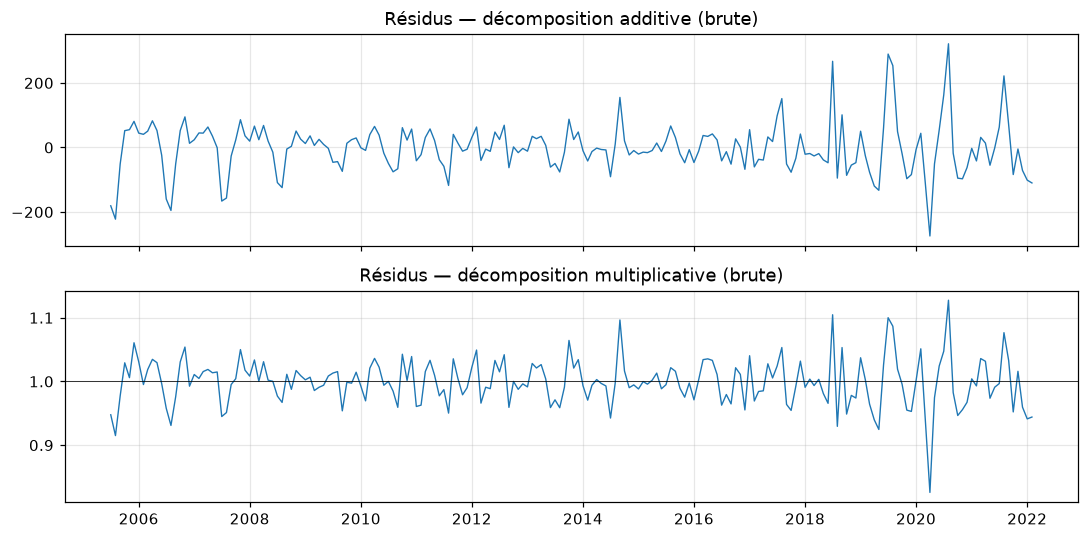

écart-type relatif des résidus  additif : 0.052 | multiplicatif : 0.037


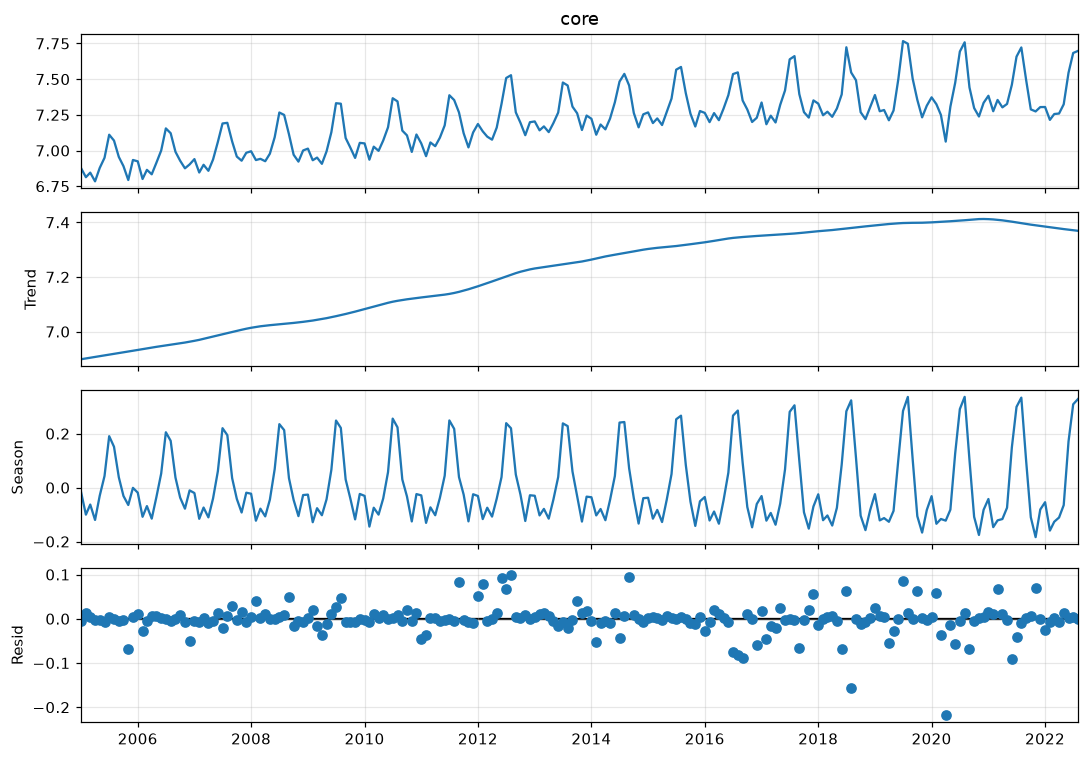

effet saisonnier moyen (log) par mois : {1: -0.03, 2: -0.123, 3: -0.088, 4: -0.118, 5: -0.052, 6: 0.074, 7: 0.255, 8: 0.256, 9: 0.066, 10: -0.059, 11: -0.13, 12: -0.044}
force de la saisonnalité = 0.94 | force de la tendance = 0.96 | écart-type du résidu (log) = 0.034


In [16]:
ly = np.log(train["core"])

# (a) classique additive vs multiplicative sur la série brute
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
dec_add = seasonal_decompose(train["core"], model="additive", period=12)
dec_mul = seasonal_decompose(train["core"], model="multiplicative", period=12)
ax[0].plot(dec_add.resid, lw=.9); ax[0].set_title("Résidus — décomposition additive (brute)")
ax[1].plot(dec_mul.resid, lw=.9); ax[1].axhline(1, color="k", lw=.5); ax[1].set_title("Résidus — décomposition multiplicative (brute)")
plt.tight_layout(); plt.show()
print("écart-type relatif des résidus  additif :", round((dec_add.resid / train['core']).std(), 3),
      "| multiplicatif :", round((dec_mul.resid - 1).std(), 3))

# (b) STL robuste sur log(core)
stl = STL(ly, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(10, 7); plt.tight_layout(); plt.show()
sea = stl.seasonal; res = stl.resid
print("effet saisonnier moyen (log) par mois :", sea.groupby(sea.index.month).mean().round(3).to_dict())
Fs = max(0, 1 - res.var() / (res + sea).var()); Ft = max(0, 1 - res.var() / (res + stl.trend).var())
print(f"force de la saisonnalité = {Fs:.2f} | force de la tendance = {Ft:.2f} | écart-type du résidu (log) = {res.std():.3f}")

**Interprétation des composantes (STL sur log).**
- *Tendance* : croissance lisse et monotone sur l'ensemble de la période (de ≈ 6,90 à ≈ 7,37 en log, soit environ +60 %), force ≈ 0,96 : la série n'est clairement pas stationnaire en niveau.
- *Saisonnalité* : force ≈ 0,94. Juillet et août ≈ +0,255 en log (≈ +29 % par rapport à la tendance), février et novembre ≈ −0,12/−0,13 (≈ −12 %). C'est le profil d'une demande tirée par la climatisation l'été.
- *Résidu* : écart-type ≈ 0,034 en log (environ 3,4 %), petit mais **loin d'être gaussien** (Jarque-Bera ≈ 881, p ≈ 0) à cause de quelques mois extrêmes, traités en 2.5.
- La décomposition multiplicative laisse des résidus plus homogènes que l'additive, ce qui confirme le choix du log.

### 2.3 ACF / PACF (série brute puis différenciée)

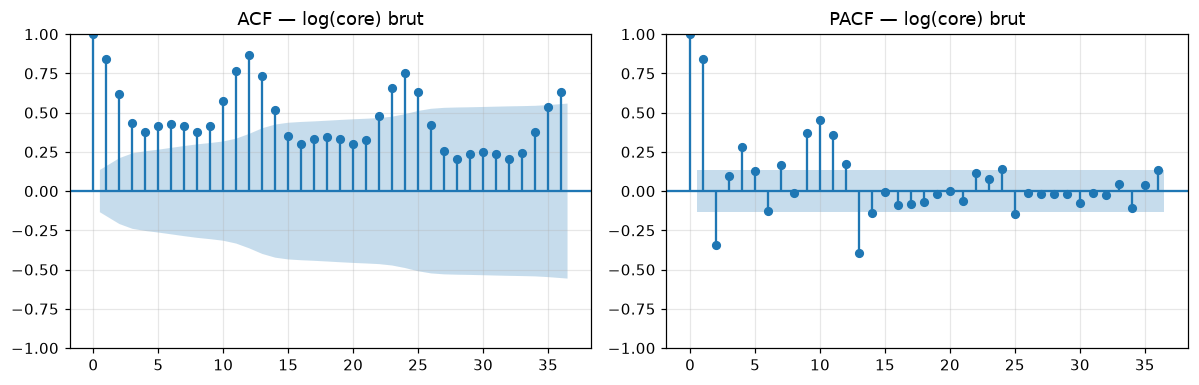

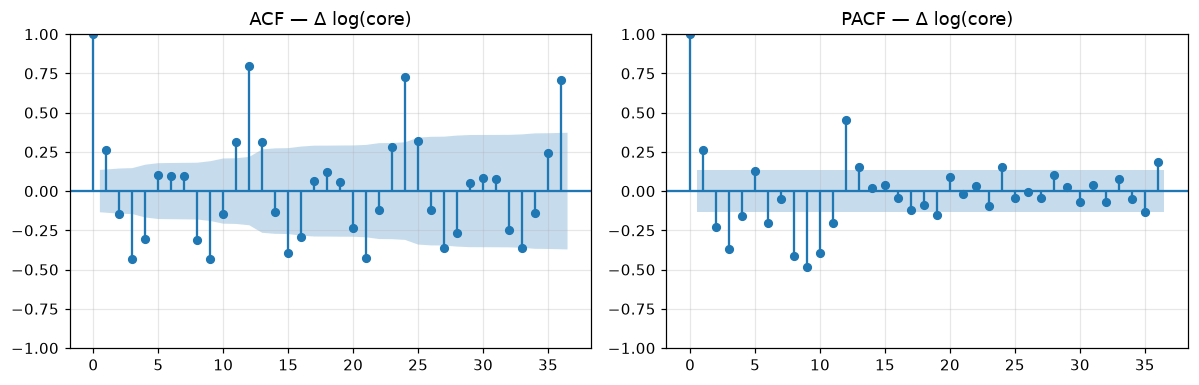

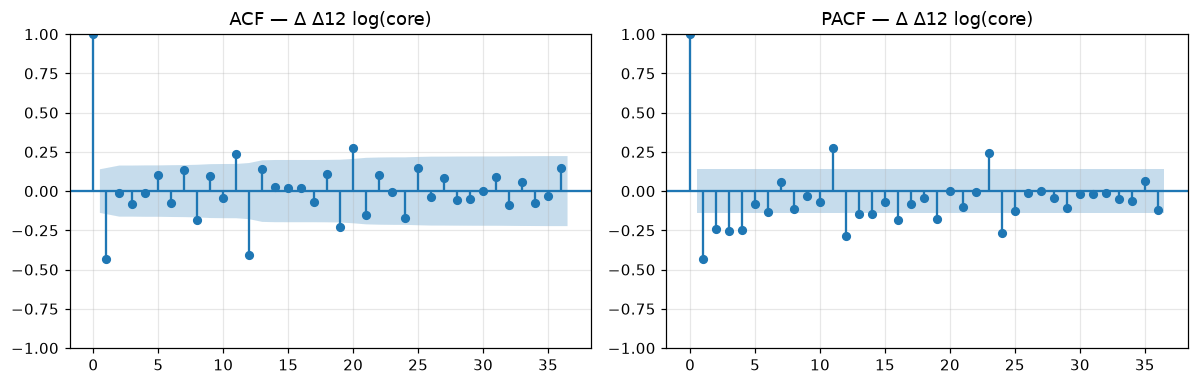

Δ log      ACF lag1/12/24 = 0.26 / 0.80 / 0.73  |  PACF lag1/12 = 0.26 / 0.46
Δ Δ12 log  ACF lag1/12/24 = -0.43 / -0.41 / -0.17  |  PACF lag1/12 = -0.43 / -0.31


In [17]:
def acf_pacf(s, title, lags=36):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    plot_acf(s.dropna(), lags=lags, ax=ax[0], title=f"ACF — {title}")
    plot_pacf(s.dropna(), lags=lags, ax=ax[1], method="ywm", title=f"PACF — {title}")
    plt.tight_layout(); plt.show()

d1 = ly.diff()                 # différence régulière
d1D12 = ly.diff().diff(12)     # + différence saisonnière
acf_pacf(ly, "log(core) brut")
acf_pacf(d1, "Δ log(core)")
acf_pacf(d1D12, "Δ Δ12 log(core)")

for name, s in [("Δ log", d1), ("Δ Δ12 log", d1D12)]:
    a, p = acf(s.dropna(), nlags=24), pacf(s.dropna(), nlags=24)
    print(f"{name:10s} ACF lag1/12/24 = {a[1]:.2f} / {a[12]:.2f} / {a[24]:.2f}  |  PACF lag1/12 = {p[1]:.2f} / {p[12]:.2f}")

**Interprétation (écrite, pas seulement affichée).**
- **Série brute (log)** : l'ACF est significative sur au moins les 15 premiers retards et décroît très lentement → non-stationnarité (tendance), avec des bosses à 12, 24, 36 → saisonnalité annuelle.
- **Après Δ (différence régulière)** : la tendance a disparu (ACF lag 1 ≈ 0,26) mais l'ACF reste très élevée aux retards saisonniers (≈ 0,80 à 12 ; ≈ 0,73 à 24) → il faut aussi une **différence saisonnière** (D = 1, s = 12).
- **Après Δ Δ12** : l'ACF ne garde que quelques pics (lag 1 ≈ −0,43 et lag 12 ≈ −0,41), la PACF décroît progressivement (lag 1 ≈ −0,43, lag 12 ≈ −0,31). Un pic négatif au retard 1 et un autre au retard 12 dans l'ACF pointent vers un **MA(1) régulier et un MA(1) saisonnier** : candidat de départ **SARIMA(0,1,1)(0,1,1)₁₂** (le « modèle airline »), à comparer ensuite aux variantes proposées par la recherche automatique.

### 2.4 Tests de stationnarité (ADF *et* KPSS)

In [18]:
def stationarity(s, name, reg="c"):
    s = s.dropna()
    a = adfuller(s, regression=reg, autolag="AIC")
    k = kpss(s, regression=reg, nlags="auto")
    adf_rej, kpss_rej = a[1] < .05, k[1] < .05      # H0 ADF : racine unitaire ; H0 KPSS : stationnaire
    verdict = ("stationnaire" if adf_rej and not kpss_rej else
               "NON stationnaire" if (not adf_rej) and kpss_rej else
               "contradictoire (ADF rejette, KPSS rejette)" if adf_rej and kpss_rej else
               "non concluant (aucun test ne rejette)")
    return dict(série=name, spec="const." if reg == "c" else "const.+tend.", ADF_stat=round(a[0], 2), ADF_p=round(a[1], 3),
                KPSS_stat=round(k[0], 2), KPSS_p=round(k[1], 3), verdict=verdict)

rows = [stationarity(train["core"], "core (brut)"),
        stationarity(train["core"], "core (brut)", "ct"),
        stationarity(ly, "log core"), stationarity(ly, "log core", "ct"),
        stationarity(d1, "Δ log core"),
        stationarity(ly.diff(12), "Δ12 log core"),
        stationarity(d1D12, "Δ Δ12 log core"),
        stationarity(train["t_mean"], "t_mean"), stationarity(train["t_mean"], "t_mean", "ct"),
        stationarity(train["t_max_mean"], "t_max_mean"), stationarity(train["t_max_mean"], "t_max_mean", "ct")]
pd.DataFrame(rows).set_index("série")

,spec,ADF_stat,ADF_p,KPSS_stat,KPSS_p,verdict
série,,,,,,
core (brut),const.,-1.88,0.343,2.31,0.010,NON stationnaire
core (brut),const.+tend.,-0.40,0.987,0.08,0.100,non concluant (aucun test ne rejette)
log core,const.,-3.03,0.032,2.31,0.010,"contradictoire (ADF rejette, KPSS rejette)"
log core,const.+tend.,0.51,0.997,0.16,0.041,NON stationnaire
Δ log core,const.,-7.20,0.000,0.09,0.100,stationnaire
Δ12 log core,const.,-4.10,0.001,0.74,0.010,"contradictoire (ADF rejette, KPSS rejette)"
Δ Δ12 log core,const.,-6.61,0.000,0.18,0.100,stationnaire
t_mean,const.,-2.84,0.053,0.05,0.100,non concluant (aucun test ne rejette)
t_mean,const.+tend.,-4.06,0.007,0.01,0.100,stationnaire


**Conclusion sur l'ordre de différenciation.**
- **core brut** : ADF ne rejette pas la racine unitaire (p ≈ 0,34) et KPSS rejette la stationnarité → non stationnaire.
- **log core** : avec constante seule, ADF rejette (p ≈ 0,03) mais KPSS aussi → résultat contradictoire ; avec tendance, ADF ne rejette pas (p ≈ 1) → on conclut à la non-stationnarité (tendance stochastique).
- **Δ log core** : ADF rejette, KPSS ne rejette pas → stationnaire en tendance. Mais l'ACF a montré une saisonnalité résiduelle (Δ12 seule reste contradictoire).
- **Δ Δ12 log core** : les deux tests concordent sur la stationnarité.
- ⇒ **ordre retenu : d = 1 et D = 1 (s = 12)**, sur le log de la série.
- **Température** (`t_mean`, `t_max_mean`) : avec tendance, l'ADF rejette la racine unitaire (p < 0,05) et KPSS ne rejette pas → **stationnaire autour d'un profil saisonnier** (sans constante seule, l'ADF est limite à cause de la saisonnalité). *Conséquence pour la section 3.2* : la production est I(1) alors que la température est stationnaire ; une relation de **cointégration au sens strict entre production et température est donc a priori improbable**. On le testera quand même (Johansen) et on rapportera honnêtement le résultat ; une autre paire cointégrable ou une sous-période pourra être cherchée.

### 2.5 Valeurs aberrantes

mois hors IQR : 40 / 212 (19%) | |z robuste| > 3,5 : 35


,résidu STL (log),z robuste,anomalie t_max (°C),jours >35°C
month,,,,
2020-04-01,-0.218,-19.3,0.7,0
2018-08-01,-0.156,-13.9,-2.0,2
2012-08-01,0.099,8.8,1.2,12
2014-09-01,0.094,8.3,1.8,1
2012-06-01,0.092,8.2,1.2,4
2021-06-01,-0.091,-8.0,2.3,7
2016-09-01,-0.088,-7.8,-1.2,0
2019-07-01,0.085,7.5,1.8,14


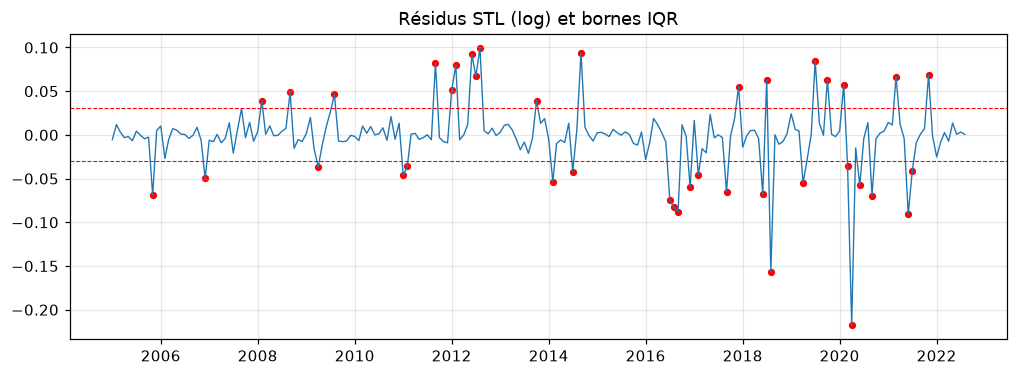

corr(résidu STL, anomalie t_mean        ) = 0.09
corr(résidu STL, anomalie t_max_mean    ) = 0.09
corr(résidu STL, anomalie days_above_35 ) = 0.15
corr(résidu STL, anomalie cdd24         ) = 0.28


In [19]:
res = STL(ly, period=12, robust=True).fit().resid
q1, q3 = res.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mad_z = (res - res.median()) / (1.4826 * (res - res.median()).abs().median())   # z robuste (MAD)

clim = train["t_max_mean"].groupby(train.index.month).transform("mean")
tab = pd.DataFrame({"résidu STL (log)": res.round(3), "z robuste": mad_z.round(1),
                    "anomalie t_max (°C)": (train["t_max_mean"] - clim).round(1),
                    "jours >35°C": train["days_above_35"]})
flag_iqr = (res < lo) | (res > hi)
print(f"mois hors IQR : {int(flag_iqr.sum())} / {len(res)} ({flag_iqr.mean():.0%}) | |z robuste| > 3,5 : {int((mad_z.abs() > 3.5).sum())}")
display(tab.loc[mad_z.abs().sort_values(ascending=False).index[:8]])

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(res.index, res, lw=.9); ax.axhline(lo, color="r", ls="--", lw=.7); ax.axhline(hi, color="r", ls="--", lw=.7)
ax.scatter(res.index[flag_iqr], res[flag_iqr], color="r", s=14); ax.set_title("Résidus STL (log) et bornes IQR")
plt.show()

# les résidus sont-ils expliqués par les anomalies de température ?
for c in ["t_mean", "t_max_mean", "days_above_35", "cdd24"]:
    an = train[c] - train[c].groupby(train.index.month).transform("mean")
    print(f"corr(résidu STL, anomalie {c:14s}) = {np.corrcoef(res, an)[0, 1]:.2f}")

**Diagnostic et traitement.**
- Le critère IQR signale ≈ 40 mois sur 212 (≈ 19 %) : trop pour parler d'anomalies. Cela vient des queues épaisses des résidus (non gaussiens), pas d'erreurs de saisie ; le z robuste (MAD) donne le même classement.
- **Avril 2020** est de loin le plus extrême (résidu ≈ −0,22, z ≈ −19) : il coïncide avec la période de confinement liée au COVID-19 → **traitement : variable indicatrice** `covid_2020_04` (créée dans le jeu de données), pas de suppression de la valeur.
- **Août 2018** (≈ −0,16) et l'été 2016 (≈ −0,08) sont des mois plus frais que la normale (août 2018 : température max moyenne 31,4 °C contre 33,4 °C de normale ; seulement 2 jours > 35 °C) : ce sont des **signaux réels** de la relation chaleur → production. **Conservation**.
- Les anomalies de température n'expliquent qu'une part modeste du résidu (corrélation ≈ 0,28 avec les degrés-jours, < 0,15 pour les autres) : d'autres facteurs (économie, coupures, calendrier) jouent.
- **Décision** : toutes les valeurs sont conservées sauf l'indicatrice COVID d'avril 2020 ; la non-normalité des résidus sera rappelée dans les diagnostics ARIMA et GARCH.

## 3. Synthèse et décisions pour la modélisation
| Décision | Choix | Justification |
|---|---|---|
| Série cible | `core = STEG + IPP` | définition constante (pas de rupture 2022–2023) |
| Transformation | logarithme | saisonnalité multiplicative (amplitude ∝ niveau) |
| Différenciation | d = 1, D = 1, s = 12 | ADF + KPSS concordants après Δ Δ12 |
| Modèle de départ | SARIMA(0,1,1)(0,1,1)₁₂ | ACF : pics négatifs aux retards 1 et 12 |
| Valeurs aberrantes | conservées, indicatrice avril 2020 | pics expliqués (COVID, étés frais) |
| Variables exogènes | `days_above_35`, `cdd24` (SARIMAX / LSTM) ; `t_mean` ou `t_max_mean` (VAR) | zéros en hiver → inadaptés au log/VAR |
| Cointégration | à tester, résultat négatif probable | température stationnaire vs production I(1) |
| Split | train janv. 2005 – août 2022 (212) / test sept. 2022 – août 2024 (24) | règle 90/10 chronologique |

**Limites déjà identifiées** : production ≠ consommation (imports d'Algérie et pertes non inclus) ; demande *censurée* lors des délestages (la production mesurée sous-estime la demande réelle au pic) ; température issue d'une réanalyse sur un seul point ; le test contient des pics jamais vus à l'apprentissage.